In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Flatten,Dense
from tensorflow.keras.optimizers import SGD
import matplotlib.pyplot as plt

In [ ]:
(x_train,y_train),(x_test,y_test) = keras.datasets.mnist.load_data()
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(x_train.max())
print(x_train.min())

1.0
0.0


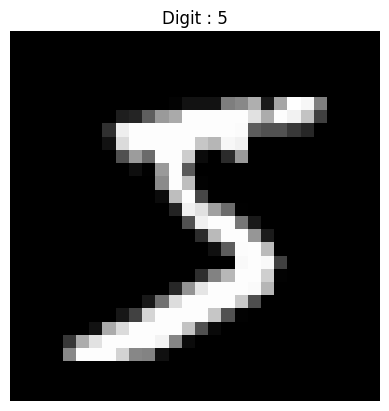

In [ ]:
plt.imshow(x_train[0],cmap='gray')
plt.title("Digit : 5")
plt.axis("off")
plt.show()

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation = "relu"),
    layers.Dense(10,activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
sgd = SGD(learning_rate = 0.01)
model.compile(
    optimizer = "sgd",
    loss = "sparse_categorical_crossentropy",
    metrics = ['accuracy']
)

history = model.fit(
    x_train,y_train,
    validation_data = (x_test,y_test),
    epochs = 10,

    batch_size = 32
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8370 - loss: 0.6238 - val_accuracy: 0.9089 - val_loss: 0.3220
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9165 - loss: 0.2966 - val_accuracy: 0.9296 - val_loss: 0.2507
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9312 - loss: 0.2442 - val_accuracy: 0.9368 - val_loss: 0.2197
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9409 - loss: 0.2107 - val_accuracy: 0.9443 - val_loss: 0.1905
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9470 - loss: 0.1861 - val_accuracy: 0.9462 - val_loss: 0.1814
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9527 - loss: 0.1666 - val_accuracy: 0.9517 - val_loss: 0.1584
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9576 - loss: 0.1503 - val_accuracy: 0.9567 - val_loss: 0.1445
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9619 - loss: 0.1366 - 

In [ ]:
test_loss , test_accuracy = model.evaluate(x_test,y_test)
print (test_loss)
print(test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9633 - loss: 0.1200
0.11995823681354523
0.9632999897003174


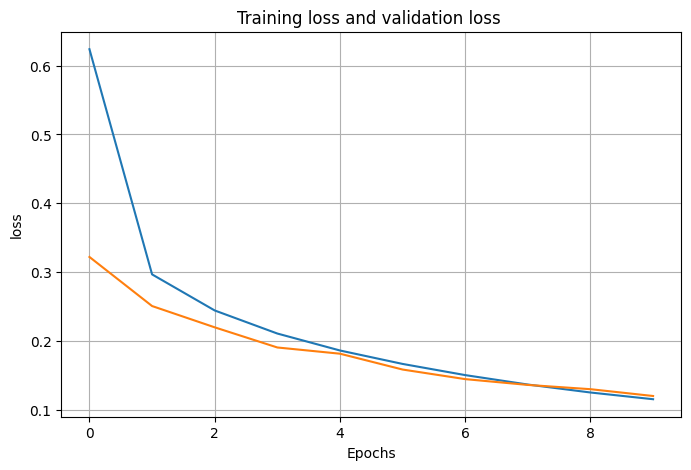

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"],label = "loss")
plt.plot(history.history["val_loss"],label = "validation  loss")
plt.grid()
plt.title("Training loss and validation loss ")
plt.xlabel("Epochs")
plt.ylabel("loss")
plt.show()

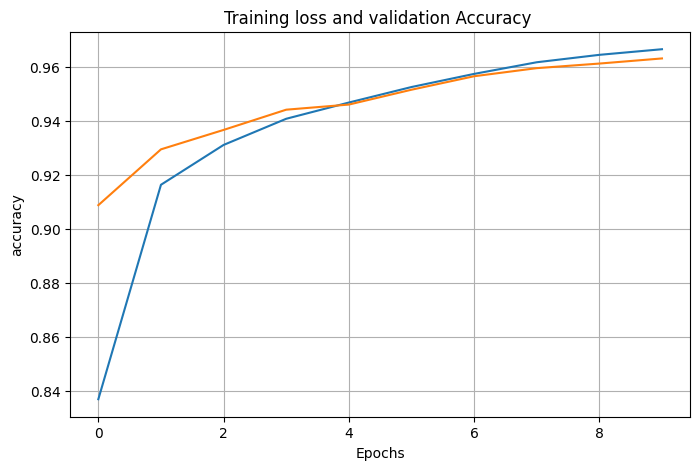

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"],label = "loss")
plt.plot(history.history["val_accuracy"],label = "validation  loss")
plt.grid()
plt.title("Training loss and validation Accuracy ")
plt.xlabel("Epochs")
plt.ylabel("accuracy")
plt.show()